<a href="https://colab.research.google.com/github/PixelPixe/Skin-Lesion-Segmentation-and-Classification-using-Deep-Learning/blob/main/HAMConvnext.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Path to dataset files: /kaggle/input/skin-cancer-mnist-ham10000


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/HAM10000_segmented.zip"
EXTRACT_PATH = "/content/HAM10000_segmented"

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Done")

Done


In [ ]:
print(len(os.listdir(EXTRACT_PATH)))

10015


In [ ]:
import pandas as pd

HAM_PATH = "/kaggle/input/skin-cancer-mnist-ham10000"

metadata = pd.read_csv(
    f"{HAM_PATH}/HAM10000_metadata.csv"
)

In [ ]:
metadata['segmented_path'] = metadata['image_id'].apply(
    lambda x: os.path.join(
        EXTRACT_PATH,
        x + ".jpg"
    )
)

In [ ]:
print(metadata['segmented_path'].iloc[0])
print(os.path.exists(metadata['segmented_path'].iloc[0]))

/content/HAM10000_segmented/ISIC_0027419.jpg
True


Change it into the all 7 lesions


Always check and number of images


In [ ]:
from sklearn.model_selection import train_test_split
df = metadata.copy()

df['target'] = (
    df['dx'] == 'mel'
).astype(int)

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['target'],
    random_state=42
)

In [ ]:
print(train_df['target'].value_counts())
print(test_df['target'].value_counts())

target
0    7122
1     890
Name: count, dtype: int64
target
0    1780
1     223
Name: count, dtype: int64


In [ ]:
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2
)

test_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [ ]:
BATCH_SIZE = 32
CLS_SIZE = 224

train_generator = train_gen.flow_from_dataframe(
    train_df,
    x_col='segmented_path',
    y_col='target',
    target_size=(CLS_SIZE, CLS_SIZE),
    class_mode='raw',
    batch_size=BATCH_SIZE
)

test_generator = test_gen.flow_from_dataframe(
    test_df,
    x_col='segmented_path',
    y_col='target',
    target_size=(CLS_SIZE, CLS_SIZE),
    class_mode='raw',
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 8012 validated image filenames.
Found 2003 validated image filenames.


In [ ]:
from tensorflow.keras.applications import ConvNeXtTiny

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    BatchNormalization
)

from tensorflow.keras.models import Model

In [ ]:
base_model = ConvNeXtTiny(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

# Freeze most layers initially
for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    layer.trainable = True

x = base_model.output

x = GlobalAveragePooling2D()(x)

x = BatchNormalization()(x)

x = Dense(
    256,
    activation='relu'
)(x)

x = Dropout(0.5)(x)

output = Dense(
    1,
    activation='sigmoid'
)(x)

model = Model(
    inputs=base_model.input,
    outputs=output
)

model.summary()

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_pres… │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stem  │ (None, 56, 56,    │      4,896 │ convnext_tiny_pr… │
│ (Sequential)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ convnext_tiny_st… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st… │
│ (LayerScale)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│                     │ 96)               │            │ convnext_tiny_st… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ add[0][0]         │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st

 Total params: 28,020,321 (106.89 MB)

 Trainable params: 16,872,705 (64.36 MB)

 Non-trainable params: 11,147,616 (42.52 MB)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['target']),
    y=train_df['target']
)

class_weights = {
    0: class_weights[0],
    1: class_weights[1]
}

print(class_weights)

{0: np.float64(0.562482448750351), 1: np.float64(4.501123595505618)}


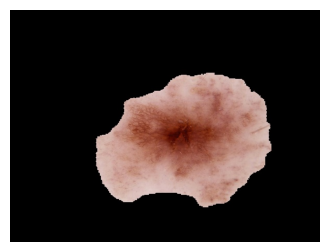

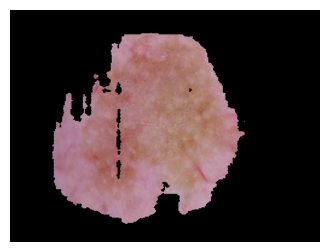

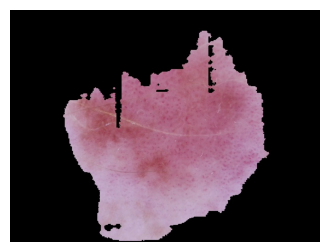

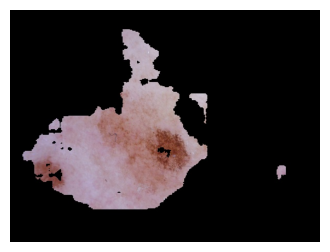

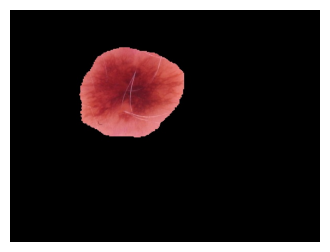

In [ ]:
import matplotlib.pyplot as plt
import cv2
import random

for i in range(5):
    idx = random.randint(0, len(train_df)-1)

    img = cv2.imread(train_df.iloc[idx]['segmented_path'])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import AUC

model.compile(
    optimizer=Adam(5e-5),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        AUC(name='auc')
    ]
)

In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

reduce_lr = ReduceLROnPlateau(
    monitor='val_auc',
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        'best_convnext.keras',
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_auc',
        mode='max',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

In [ ]:
history = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=40,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/40
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 586ms/step - accuracy: 0.6967 - auc: 0.7142 - loss: 0.6548
Epoch 1: val_auc improved from None to 0.82632, saving model to best_convnext.keras

Epoch 1: finished saving model to best_convnext.keras
251/251 ━━━━━━━━━━━━━━━━━━━━ 196s 663ms/step - accuracy: 0.6955 - auc: 0.7760 - loss: 0.5954 - val_accuracy: 0.8622 - val_auc: 0.8263 - val_loss: 0.5220 - learning_rate: 5.0000e-05
Epoch 2/40
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 530ms/step - accuracy: 0.7208 - auc: 0.8282 - loss: 0.4982
Epoch 2: val_auc improved from 0.82632 to 0.85065, saving model to best_convnext.keras

Epoch 2: finished saving model to best_convnext.keras
251/251 ━━━━━━━━━━━━━━━━━━━━ 143s 571ms/step - accuracy: 0.7249 - auc: 0.8379 - loss: 0.4930 - val_accuracy: 0.7838 - val_auc: 0.8506 - val_loss: 0.4262 - learning_rate: 5.0000e-05
Epoch 3/40
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 546ms/step - accuracy: 0.7326 - auc: 0.8488 - loss: 0.4853
Epoch 3: val_auc improved from 0.85065 to 0.86786, 

In [ ]:
from tensorflow.keras.models import load_model

best_model = load_model("best_convnext.keras")

In [ ]:
print(metadata['dx'].value_counts())

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [ ]:
metadata['target'] = metadata['dx'].apply(
    lambda x: 1 if x == 'mel' else 0
)

print(metadata['target'].value_counts())

target
0    8902
1    1113
Name: count, dtype: int64


In [ ]:
pred_probs = model.predict(test_generator)

print("Min:", pred_probs.min())
print("Max:", pred_probs.max())
print("Mean:", pred_probs.mean())

63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 205ms/step
Min: 7.92252e-06
Max: 0.9979966
Mean: 0.28292695


In [ ]:
pred_probs = best_model.predict(test_generator)

preds = (pred_probs > 0.5).astype(int)

63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 219ms/step


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        test_df['target'],
        preds
    )
)

              precision    recall  f1-score   support

           0       0.97      0.79      0.87      1780
           1       0.32      0.78      0.46       223

    accuracy                           0.79      2003
   macro avg       0.64      0.79      0.66      2003
weighted avg       0.90      0.79      0.83      2003



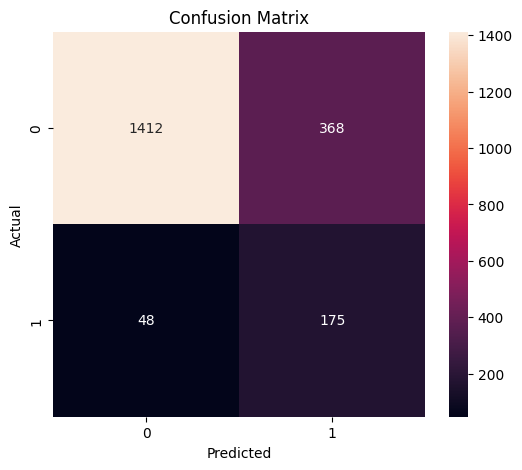

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    test_df['target'],
    preds
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

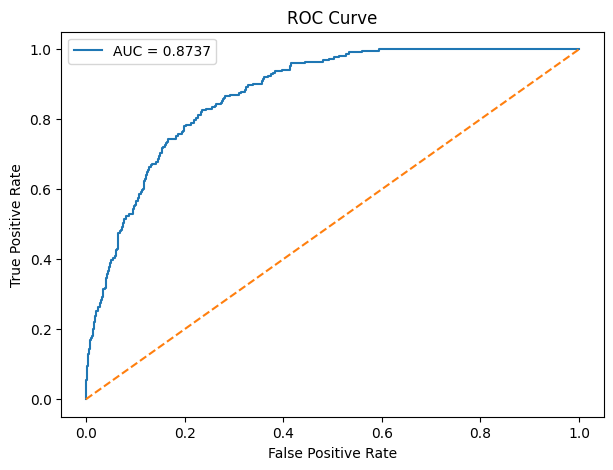

AUC: 0.8737365848742883


In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(
    test_df['target'],
    pred_probs
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

print("AUC:", roc_auc)

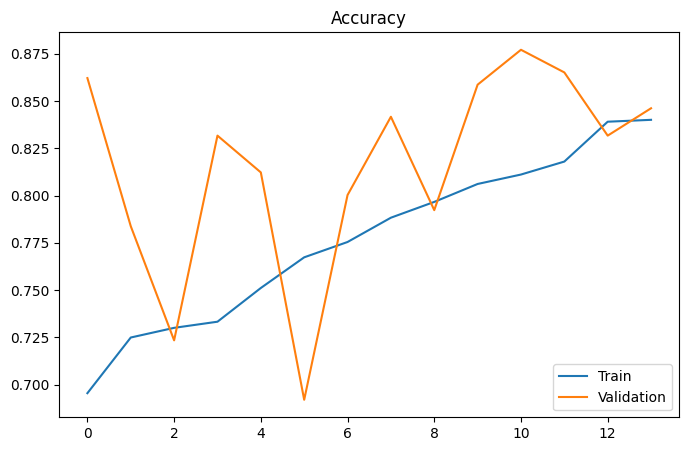

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train','Validation'])
plt.title('Accuracy')
plt.savefig('accuracy.png')
plt.show()

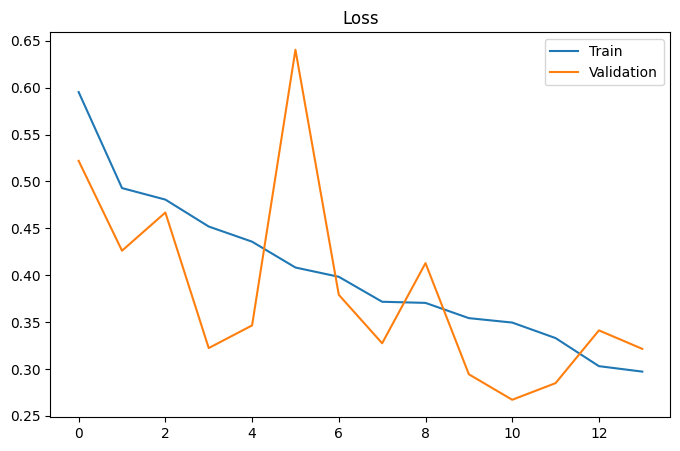

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['Train','Validation'])
plt.title('Loss')
plt.savefig('loss.png')
plt.show()